[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AGRIdigital-Climbat/PlantillaMapa/blob/main/07_NDVI_Fenologia/01_ndvi_fenologia.ipynb)

# NDVI y fenologia: ciclo vegetativo vs. calendario agricola
## PROSUCO - CLIMBAT | Analisis por municipio de Bolivia (GEE + Colab)

> **Area de estudio = tu GeoJSON.** Este notebook usa por defecto:
>
> `RUTA_AOI = "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"` (compartido `Cualquiera con el enlace`).
> El GeoJSON **siempre manda**: al cargarse, `roi`, `ZONA['bbox']`, `ZONA['centro']`
> y `area_km2` se recalculan desde el poligono. El `bbox` de CONFIG solo es respaldo
> si cambias a `AOI_MODE = "bbox"`.

**Orden de ejecucion:** 1) Instalacion -> 2) Autenticacion GEE (`EE_PROJECT`) ->
3) CONFIG (anos + satelite + umbrales) -> 4) AOI desde Drive -> 5) celdas del modulo.
Solo edita la celda **CONFIGURACION MAESTRA**.


In [27]:
# ============================================================
# 1.1 Instalación de librerías (ejecutar una sola vez en Colab)
# ============================================================

import importlib
import subprocess
import sys


def _asegurar(paquete, modulo=None):
    """Instala el paquete solo si no está disponible."""
    try:
        importlib.import_module(modulo or paquete)
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", paquete]
        )


_asegurar("earthengine-api", "ee")
_asegurar("geemap")
_asegurar("geopandas")
_asegurar("pandas")
_asegurar("numpy")
_asegurar("matplotlib")

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

print("Librerías listas.")
print("earthengine-api:", ee.__version__)
print("geemap:", geemap.__version__)

Librerías listas.
earthengine-api: 1.7.39
geemap: 0.38.8


In [28]:
# ============================================================
# 1.2 Autenticación en Google Earth Engine
# ============================================================
# >>> REEMPLAZAR por el id del proyecto de Cloud de PROSUCO/CLIMBAT <<<

EE_PROJECT = "gen-lang-client-0636031685"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

print("Earth Engine inicializado correctamente.")
print("Proyecto:", EE_PROJECT)

Earth Engine inicializado correctamente.
Proyecto: gen-lang-client-0636031685


## Configuración maestra

> **✏️ Esta es la única celda que se edita para diagnosticar una zona nueva.**

| Bloque | Qué define | Verificación previa |
|---|---|---|
| `ZONA` | nombre, bbox `[oeste, sur, este, norte]` y punto de vista | dibujar en [geojson.io](https://geojson.io) o en el editor GEE y copiar coordenadas |
| `AOI_MODE`/`RUTA_AOI` | fuente del AOI: `"bbox"` o `"auto"` (polígono **GeoJSON**) | exportar el polígono desde QGIS como **GeoJSON**; en `RUTA_AOI` se puede pegar un **enlace de Google Drive** (el notebook lo descarga solo) o una ruta de Drive |
| `PUNTOS_LOCALES` | manantiales/bofedales del saber local | levantamiento con las comunidades |
| `FECHA_INICIO / FECHA_FIN` | ventana analítica (**30+ años**) | default 1996-01-01 → 2026-12-31 |
| `CALENDARIO` | meses de siembra/cosecha y estación seca | observadores Yapuchiri |
| `UMBRALES` | todos los cortes analíticos en un solo lugar | criterio técnico + experiencia local |
| `ESCALAS` | resolución de cómputo (m); subir si la zona es grande | — |

In [29]:
# ===========================================================================
# CONFIGURACIÓN MAESTRA — ÚNICA CELDA QUE SE EDITA PARA CADA ZONA
# ===========================================================================

# --- 1. Zona de intervención ------------------------------------------------
# Fuente del AOI:
#   "bbox" -> usa el rectángulo ZONA["bbox"] de abajo (rápido, sin Drive)
#   "auto" -> usa un polígono .geojson. RUTA_AOI admite 3 formas:
#       * Enlace o ID de Google Drive  -> se DESCARGA solo (no subes nada a mano)
#           "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"
#           "11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N"
#       * Ruta en tu Drive ya montado  -> se lee directo, SIN copiar a /content
#           "/content/drive/MyDrive/CLIMBAT/zona.geojson"
#       * Carpeta en Drive             -> toma el único .geojson que contenga
#           "/content/drive/MyDrive/CLIMBAT"
AOI_MODE = "auto"
RUTA_AOI = "https://drive.google.com/file/d/1d_mzsDO39gPBXwk-DAPD65JXsHBW5agD/view?usp=sharing"

ZONA = {
    # Coordenadas geocodificadas: Escoma (La Paz, Bolivia) ~3832 msnm
    # (solo se usan como respaldo cuando AOI_MODE = "bbox")
    "nombre": "Escoma, La Paz (prueba)",
    "bbox": [-69.33, -15.86, -68.93, -15.46],   # [oeste, sur, este, norte]
    "centro": [-69.1289, -15.6615],             # punto de vista del mapa
    "zoom": 10,
}

# --- 2. Puntos levantados con comunidades (saber local) ---------------------
# Listas de [longitud, latitud]. Dejar vacías si aún no hay levantamiento.
PUNTOS_LOCALES = {
    "manantiales": [],
    "bofedales": [],
}

# --- 3. Ventana analítica: 30+ años hacia atrás desde el año actual ---------
# Regla de la plantilla: 1996-01-01 -> 2026-12-31 (todo análisis de rango de años usa esta).
# Los datasets usan su período nativo si es mayor: CHIRPS 1981+ · ERA5-Land 1950+
# · JRC 1984–2021 · MODIS 2000+ (NDVI) / 2001+ (MCD12Q1 agricultura) · SMAP 2015+
FECHA_INICIO = "1996-01-01"
FECHA_FIN = "2026-12-31"

# --- 4. Calendario agrícola local (verificar con observadores Yapuchiri) ----
CALENDARIO = {
    "siembra": 11,       # mes de siembra (1–12)
    "cosecha": 4,        # mes de cosecha (1–12)
    "meses_estacion_seca": [5, 6, 7, 8, 9, 10],   # se usa en M10 (bofedales)
}

# --- 5. Umbrales analíticos (ajustar con criterio técnico y local) ----------
UMBRALES = {
    "helada_c": 0.0,               # °C mínima para contar un día de helada (M4)
    "helada_grave_c": -2.0,        # °C de helada grave (daño severo) (M4)
    "mes_seco_mm": 30.0,           # mm/mes para clasificar mes seco (M2)
    "spi_severo": -1.5,            # umbral de sequía severa SPI-3 (M5)
    "ndvi_anomalia_z": -1.5,       # anomalía NDVI severa (M7)
    "manantial_occurrencia": 100,  # % ocurrencia JRC mínima (M9)
    "manantial_drenaje_max": 50,   # celdas acumuladas máx. (cabeceras) (M9)
    "bofedal_altitud_min": 3000,   # msnm mínimo (M10)
    "bofedal_altitud_max": 5200,   # msnm máximo (M10)
    "bofedal_pendiente_max": 5.0,  # grados de pendiente máxima (M10)
    "bofedal_seasonality": 8,      # meses con agua JRC mínimos (M10)
    "bofedal_ndvi_seco": 0.25,     # NDVI mínimo en estación seca (M10)
    "clases_agricolas": [12, 14],  # LC_Type1 MCD12Q1: 12=cultivos, 14=mosaico (M11)
}

# --- 6. Escalas de cómputo (metros) -----------------------------------------
# Subir si la zona es muy grande (más rápido, menos detalle)
ESCALAS = {"clima": 5000, "modis": 250, "jrc": 90, "detalle": 30}
TILE_SCALE = 4

# ===========================================================================
# A partir de aquí no se edita nada
# ===========================================================================

MESES = list(range(1, 13))
MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
            "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

roi = None   # se construye en la celda 1.4 (bbox o GeoJSON según AOI_MODE)
centro = None
ANIO_INI = int(FECHA_INICIO[:4])
ANIO_FIN = int(FECHA_FIN[:4])

# Años COMPLETOS (se excluye el año en curso de métricas y mapas anuales)
ANIOS_COMPLETOS = list(range(ANIO_INI, ANIO_FIN))
FILTRO_ANIOS_COMPLETOS = ee.Filter.calendarRange(
    ANIOS_COMPLETOS[0], ANIOS_COMPLETOS[-1], "year"
)

print("Zona:", ZONA["nombre"])
print("Ventana analítica:", FECHA_INICIO, "->", FECHA_FIN,
      f"({ANIO_FIN - ANIO_INI + 1} años calendario)")
print("Años completos para métricas:", ANIOS_COMPLETOS[0], "-", ANIOS_COMPLETOS[-1])
print("Calendario: siembra mes", CALENDARIO["siembra"],
      "| cosecha mes", CALENDARIO["cosecha"])
print("Umbrales activos:", UMBRALES)

Zona: Escoma, La Paz (prueba)
Ventana analítica: 1996-01-01 -> 2026-12-31 (31 años calendario)
Años completos para métricas: 1996 - 2025
Calendario: siembra mes 11 | cosecha mes 4
Umbrales activos: {'helada_c': 0.0, 'helada_grave_c': -2.0, 'mes_seco_mm': 30.0, 'spi_severo': -1.5, 'ndvi_anomalia_z': -1.5, 'manantial_occurrencia': 100, 'manantial_drenaje_max': 50, 'bofedal_altitud_min': 3000, 'bofedal_altitud_max': 5200, 'bofedal_pendiente_max': 5.0, 'bofedal_seasonality': 8, 'bofedal_ndvi_seco': 0.25, 'clases_agricolas': [12, 14]}


In [30]:
# ============================================================
# 1.3 Utilidades comunes (reutilizadas por todos los módulos)
# ============================================================

# Parámetros de reducción seguros contra "User memory limit exceeded":
#   bestEffort=True -> GEE sube la escala automáticamente si no cabe en memoria.
#   tileScale=8     -> divide el cálculo en tiles más pequeños (menos memoria c/u).
REDUCIR = dict(maxPixels=1e9, tileScale=8, bestEffort=True)
REDUCIR_AREA = dict(maxPixels=1e10, tileScale=16, bestEffort=True)


def apilar(imagenes, nombres):
    """Une imágenes de una banda en una sola imagen multibanda."""
    pila = None
    for img, nombre in zip(imagenes, nombres):
        banda = ee.Image(img).select(0).rename(nombre)
        pila = banda if pila is None else pila.addBands(banda)
    return pila


def reducir_bandas(imagenes, nombres, escala, tam=6, reductor=None, params=None):
    """reduceRegion de muchas bandas EN BLOQUES (una petición por bloque).

    Evita el error de memoria que ocurre al reducir de una sola vez una imagen
    con decenas de bandas (cada banda puede depender de cientos/miles de imágenes
    diarias). Devuelve un dict {nombre_banda: valor}.
    """
    reductor = reductor or ee.Reducer.mean()
    params = params or REDUCIR
    salida = {}
    for i in range(0, len(imagenes), tam):
        pila = apilar(imagenes[i:i + tam], nombres[i:i + tam])
        salida.update(
            pila.reduceRegion(reductor, roi, escala, **params).getInfo()
        )
    return salida


def composite_mensual(coleccion, anios, banda=None):
    """Reduce una colección diaria a UN compuesto por año-mes (una imagen c/u).

    Aligera ~30x la memoria de las climatologías de 30 años. `anios` debe listar
    solo años con dato (evita colecciones vacías). Con `banda`, deja una sola banda.
    """
    imgs = []
    for y in anios:
        for m in MESES:
            i0 = f"{y}-{m:02d}-01"
            i1 = (pd.Timestamp(i0) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
            sub = coleccion.filterDate(i0, i1)
            if banda:
                sub = sub.select(banda)
            imgs.append(sub.mean().set("system:time_start", ee.Date(i0).millis()))
    return ee.ImageCollection(imgs)


def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente).

    Evita que el relleno de color tape el mapa y meta ruido en la interpretación;
    deja el límite del área bien visible por encima de las demás capas.
    """
    return roi.style(color=color, fillColor="00000000", width=ancho)


def promediar_aoi(imagen, banda, escala):
    """Promedio de una banda dentro del AOI -> valor Python (o None)."""
    d = (
        imagen.select(banda)
        .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        .getInfo()
    )
    return d.get(banda)


def serie_aoi(coleccion, banda, escala, bloque_anios=5):
    """Extrae el promedio del AOI por imagen, EN BLOQUES de años.

    Procesar la serie completa de una vez agota la memoria; por eso se trocea
    (por defecto cada 5 años) y se concatenan los resultados.
    """
    registros = []

    def _una_imagen(img):
        st = (
            img.select(banda)
            .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        )
        return ee.Feature(None, {
            "date": ee.Date(img.get("system:time_start")).format("yyyy-MM-dd"),
            "valor": st.get(banda),
        })

    for y0 in range(ANIO_INI, ANIO_FIN + 1, bloque_anios):
        y1 = min(y0 + bloque_anios - 1, ANIO_FIN)
        sub = coleccion.filterDate(f"{y0}-01-01", f"{y1 + 1}-01-01")
        fc = ee.FeatureCollection(sub.map(_una_imagen)).getInfo()
        registros += [f["properties"] for f in fc["features"]]
    return registros


print("Utilidades: apilar(), reducir_bandas(), composite_mensual(), "
      "promediar_aoi(), serie_aoi()")

Utilidades: apilar(), reducir_bandas(), composite_mensual(), promediar_aoi(), serie_aoi()


In [31]:
# ============================================================
# 1.4 Área de estudio (AOI) y mapa base
# ============================================================
# Fuente del AOI (ver CONFIG):
#   AOI_MODE = "bbox" -> rectángulo ZONA["bbox"].
#   AOI_MODE = "auto" -> polígono desde un archivo .geojson en Google Drive.
#                        (En QGIS: Exportar -> Guardar entidades como -> GeoJSON,
#                         CRS EPSG:4326; subir a Drive y ajustar RUTA_AOI.)

def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente)."""
    # ee.Geometry NO tiene .style() en la API de Python -> se envuelve en FeatureCollection
    fc = ee.FeatureCollection([ee.Feature(roi)])
    return fc.style(color=color, fillColor="00000000", width=ancho)


if AOI_MODE == "auto":
    from google.colab import drive
    drive.mount("/content/drive")

    import os
    import re
    import glob
    import geopandas as gpd

    ruta = str(RUTA_AOI).strip()

    # (a) Enlace o ID de Google Drive -> descarga automática (sin subir nada a mano).
    #     El archivo debe estar compartido como "Cualquiera con el enlace".
    if ruta.startswith("http") or ("/" not in ruta and len(ruta) >= 20):
        _asegurar("gdown")
        import gdown

        m = re.search(r"(?:/d/|id=)([-\w]{20,})", ruta)
        fid = m.group(1) if m else ruta
        ext = (
            ".zip" if ruta.lower().endswith(".zip") else
            ".kml" if ruta.lower().endswith(".kml") else
            ".gpkg" if ruta.lower().endswith(".gpkg") else
            ".geojson"
        )
        destino = "/content/zona_aoi" + ext
        print("Descargando AOI desde Google Drive...")
        gdown.download(id=fid, output=destino, quiet=False)
        ruta = destino
    # (b) Carpeta en Drive -> usar el único .geojson que contenga
    elif os.path.isdir(ruta):
        cands = sorted(glob.glob(os.path.join(ruta, "*.geojson")))
        if not cands:
            raise FileNotFoundError(f"No se encontró ningún .geojson en {ruta}")
        ruta = cands[0]
    # (c) Ruta de archivo en el Drive montado -> se lee directo (sin copiar)

    gdf = gpd.read_file(ruta).to_crs(4326)
    try:
        geometria = gdf.geometry.union_all()      # shapely >= 2 (disuelve features)
    except AttributeError:
        geometria = gdf.geometry.unary_union      # shapely < 2
    gdf = gpd.GeoDataFrame(geometry=[geometria], crs=4326)

    roi = geemap.geopandas_to_ee(gdf).geometry()

    minx, miny, maxx, maxy = geometria.bounds
    ZONA["bbox"] = [minx, miny, maxx, maxy]
    ZONA["centro"] = [(minx + maxx) / 2, (miny + maxy) / 2]
    ZONA["zoom"] = 10
    print("AOI cargado desde:", ruta)
else:
    roi = ee.Geometry.Rectangle(ZONA["bbox"], proj="EPSG:4326", geodesic=False)

centro = ee.Geometry.Point(ZONA["centro"])
area_km2 = roi.area(maxError=1e6).divide(1e6).getInfo()

Map_aoi = geemap.Map()
Map_aoi.centerObject(roi, ZONA["zoom"])
Map_aoi.add_basemap("HYBRID")
Map_aoi.addLayer(borde_aoi(), {}, f"AOI: {ZONA['nombre']}")

# Puntos del saber local (si se cargaron en CONFIG)
for tipo, color in (("manantiales", "cyan"), ("bofedales", "magenta")):
    coords = PUNTOS_LOCALES.get(tipo, [])
    if coords:
        Map_aoi.addLayer(
            ee.Geometry.MultiPoint(coords),
            {"color": color},
            f"{tipo.capitalize()} (saber local)",
        )

print(f"Zona: {ZONA['nombre']}")
print(f"Área del AOI: {area_km2:,.1f} km²")
print(f"Extensión (bbox): {ZONA['bbox']}")
print("Puntos de saber local cargados:",
      {k: len(v) for k, v in PUNTOS_LOCALES.items()})

Map_aoi

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Descargando AOI desde Google Drive...


Downloading...
From: https://drive.google.com/uc?id=1d_mzsDO39gPBXwk-DAPD65JXsHBW5agD
To: /content/zona_aoi.geojson
100%|██████████| 2.16k/2.16k [00:00<00:00, 5.69MB/s]


AOI cargado desde: /content/zona_aoi.geojson
Zona: Escoma, La Paz (prueba)
Área del AOI: 353.0 km²
Extensión (bbox): [-69.326927, -15.680335, -69.071175, -15.437036]
Puntos de saber local cargados: {'manantiales': 0, 'bofedales': 0}


Map(center=[-15.55528007981374, -69.21579100925494], controls=(WidgetControl(options=['position', 'transparent…

# M7. NDVI y fenología: serie, comparación estacional y cambio NDVI
**Dimensiones:** *temporalidad* (año agrícola Y-1/Y y su calce con siembra), *estacionalidad* (curva anual M7.1),
*intensidad* (ΔNDVI M7.2), *tendencia* (serie multianual).

* **M7.1 Serie:** `COPERNICUS/S2_SR_HARMONIZED` — B4+B8 → `NDVI=(B8−B4)/(B8+B4)`, 10 m, **2017–actual**, máscara SCL.
* **M7.2 Comparación estacional (este bloque):** `LANDSAT/LC08/C02/T1_L2 + LC09` — mosaico mediana **época seca (may–sep, `CLOUD_COVER<30`)** vs **época húmeda (nov–abr, `CLOUD_COVER<60`)** del mismo año agrícola, 30 m, **2013–actual**. Adapta Day4 Sesión 2 Transcend (`02_building_the_classification_input_es`): color natural + NDVI lado a lado, bandas con sufijo `_seca/_humeda` y **ΔNDVI = húmeda − seca**.
* Sin muestras ni clasificación: solo diagnóstico visual.

<details>
<summary><b>📐 NDVI: qué es y cómo leerlo</b> — clic para ver</summary>
<br>

NDVI = (NIR − Rojo) / (NIR + Rojo), escala **−1 a 1**. Valores guía:

| NDVI | Significado |
|---|---|
| < 0,1 | agua, nieve, roca desnuda |
| 0,1–0,25 | suelo desnudo, cultivo recién sembrado |
| 0,25–0,5 | cultivo en crecimiento |
| > 0,5 | vegetación densa/saludable |

ΔNDVI = NDVI húmeda − NDVI seca: **>0,15** reverdecimiento fuerte (cultivos); **0,05–0,15** moderado (pastizal húmedo); **<0,05** sin cambio.

</details>


Imágenes Sentinel-2 en la ventana: 634
Extrayendo 634 imágenes en bloques de 200...
  · bloque 200/634 procesado
  · bloque 400/634 procesado
  · bloque 600/634 procesado
  · bloque 634/634 procesado

Observaciones válidas: 633
Rango: 2016-03-18 → 2026-10-12
Años presentes: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

NDVI pico: 0.35 en el mes 2 (Feb)
Ventana de crecimiento (NDVI >= 50% del pico): meses ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
Calendario CONFIG: siembra mes 11 | cosecha mes 4


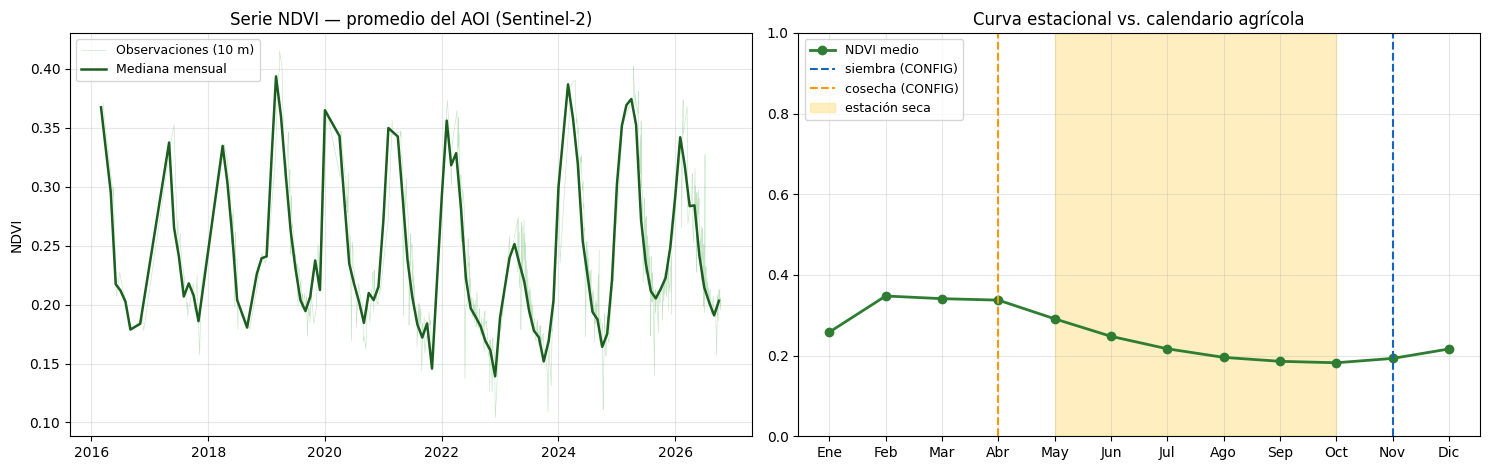

In [32]:
# ============================================================
# M7.1 Serie NDVI y curva estacional (Sentinel-2)
# Extracción autocontenida — sin depender de serie_aoi
# ============================================================

# --- 1. Carga de la colección de Sentinel-2 (SR Harmonizado) -----------------
s2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterDate(FECHA_INICIO, FECHA_FIN)
    .filterBounds(roi)
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
)

n_imagenes = s2.size().getInfo()
print(f"Imágenes Sentinel-2 en la ventana: {n_imagenes}")

if n_imagenes == 0:
    raise RuntimeError(
        f"No hay imágenes de Sentinel-2 entre {FECHA_INICIO} y {FECHA_FIN} "
        f"en el AOI. Revisa las fechas o el área de estudio."
    )

# --- 2. Función NDVI + máscara de nubes (usando la banda SCL) ----------------
def calcular_ndvi(img):
    """Calcula NDVI y enmascara nubes, sombras y nieve con la banda SCL."""
    scl = img.select('SCL')
    # SCL: 4=vegetación, 5=suelo desnudo, 6=agua, 7=no clasificado
    # Descartamos: 3=sombra de nube, 8=nube media, 9=nube alta, 10=cirros, 11=nieve
    mascara = (scl.neq(3)
               .And(scl.neq(8))
               .And(scl.neq(9))
               .And(scl.neq(10))
               .And(scl.neq(11)))
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('ndvi')
    return ndvi.updateMask(mascara).copyProperties(img, ['system:time_start'])

ndvi_col = s2.map(calcular_ndvi)

# --- 3. Extracción por bloques usando reduceRegion directamente ---------------
def extraer_ndvi(coleccion, aoi, escala=10, chunk=200):
    """Extrae la media de NDVI en el AOI para cada imagen, por bloques."""
    n = coleccion.size().getInfo()
    print(f"Extrayendo {n} imágenes en bloques de {chunk}...")
    filas = []
    lista = coleccion.toList(n)
    for i in range(0, n, chunk):
        sub = ee.ImageCollection(lista.slice(i, min(i + chunk, n)))
        def reducir(img):
            stats = ee.Image(img).reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=aoi,
                scale=escala,
                maxPixels=1e13,
                bestEffort=True,
                tileScale=8,
            )
            return ee.Feature(None, {
                'fecha': ee.Image(img).date().format('YYYY-MM-dd'),
                'valor': stats.get('ndvi'),
            })
        bloque = sub.map(reducir).getInfo()['features']
        for f in bloque:
            filas.append(f['properties'])
        print(f"  · bloque {i + chunk if i + chunk < n else n}/{n} procesado")
    return pd.DataFrame(filas)

df_ndvi = extraer_ndvi(ndvi_col, roi, escala=20)

if df_ndvi.empty:
    raise RuntimeError("No se extrajo ninguna observación de NDVI.")

# --- 4. Normalización del DataFrame ------------------------------------------
df_ndvi['fecha'] = pd.to_datetime(df_ndvi['fecha'])
df_ndvi = df_ndvi.dropna(subset=['valor']).set_index('fecha').sort_index()

print(f"\nObservaciones válidas: {len(df_ndvi)}")
print(f"Rango: {df_ndvi.index.min().date()} → {df_ndvi.index.max().date()}")
print(f"Años presentes: {sorted(df_ndvi.index.year.unique())}")

# --- 5. Serie agregada por mes (para gráfico legible) ------------------------
df_mensual = (
    df_ndvi
    .resample('MS')
    .agg({'valor': 'median'})
    .dropna()
)

# --- 6. Curva estacional (solo años completos) --------------------------------
completos = df_ndvi[df_ndvi.index.year.isin(ANIOS_COMPLETOS)]

if completos.empty:
    print("⚠ No hay datos para años en ANIOS_COMPLETOS. "
          "Usando todos los años disponibles.")
    completos = df_ndvi

clim_ndvi = completos.groupby(completos.index.month)['valor'].mean()

mes_pico_ndvi = int(clim_ndvi.idxmax())
ndvi_pico = float(clim_ndvi.max())
ventana_cre = list(clim_ndvi[clim_ndvi >= 0.5 * ndvi_pico].index)

print(f"\nNDVI pico: {ndvi_pico:.2f} en el mes {mes_pico_ndvi} "
      f"({MESES_ES[mes_pico_ndvi - 1]})")
print("Ventana de crecimiento (NDVI >= 50% del pico): meses",
      [MESES_ES[m - 1] for m in ventana_cre])
print("Calendario CONFIG: siembra mes", CALENDARIO["siembra"],
      "| cosecha mes", CALENDARIO["cosecha"])

# --- 7. Gráficos --------------------------------------------------------------
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8))

# Panel 1 — Serie temporal
ejes[0].plot(df_ndvi.index, df_ndvi['valor'], lw=0.4, alpha=0.4,
             color="#66bb6a", label="Observaciones (10 m)")
ejes[0].plot(df_mensual.index, df_mensual['valor'], lw=1.8,
             color="#1b5e20", label="Mediana mensual")
ejes[0].set_title("Serie NDVI — promedio del AOI (Sentinel-2)")
ejes[0].set_ylabel("NDVI")
ejes[0].legend(fontsize=9)
ejes[0].grid(alpha=0.3)

# Panel 2 — Curva estacional vs. calendario
ejes[1].plot(MESES, clim_ndvi.values, marker="o", lw=2, color="#2e7d32",
             label="NDVI medio")
ejes[1].axvline(CALENDARIO["siembra"], color="#1565c0", ls="--",
                label="siembra (CONFIG)")
ejes[1].axvline(CALENDARIO["cosecha"], color="#ff9800", ls="--",
                label="cosecha (CONFIG)")
ejes[1].fill_betweenx([0, 1],
                      min(CALENDARIO["meses_estacion_seca"]),
                      max(CALENDARIO["meses_estacion_seca"]),
                      color="#ffe082", alpha=0.5, label="estación seca")
ejes[1].set_title("Curva estacional vs. calendario agrícola")
ejes[1].set_xticks(MESES)
ejes[1].set_xticklabels(MESES_ES)
ejes[1].set_ylim(0, 1)
ejes[1].legend(fontsize=9)
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# M7.2b Comparacion INTERANUAL: anio mas HUMEDO vs mas SECO
# ============================================================
import ee

# --- 1) Precipitacion anual por anio (CHIRPS) ---
def precip_anual(anio):
    p = (ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
           .filterDate(f"{anio}-01-01", f"{anio + 1}-01-01")
           .filterBounds(roi)
           .select("precipitation")
           .sum())
    return p.reduceRegion(reducer=ee.Reducer.mean(),
                          geometry=roi, scale=5000,
                          maxPixels=1e9).get("precipitation")

anios = list(ANIOS_COMPLETOS)
precip_por_anio = {a: precip_anual(a).getInfo() for a in anios}
print("Precipitacion anual (mm) por anio, CHIRPS:")
for a, p in precip_por_anio.items():
    print(f"  {a}: {p:6.0f}")

ANIO_SECO   = min(precip_por_anio, key=precip_por_anio.get)
ANIO_HUMEDO = max(precip_por_anio, key=precip_por_anio.get)
print(f"\nAnio mas SECO:   {ANIO_SECO}  ({precip_por_anio[ANIO_SECO]:.0f} mm)")
print(f"Anio mas HUMEDO: {ANIO_HUMEDO} ({precip_por_anio[ANIO_HUMEDO]:.0f} mm)")


# --- 2) Coleccion Landsat multi-mision segun anio ---
def scale_rename_bands(sr_bands):
    def f(image):
        optical = image.select(sr_bands).multiply(0.0000275).add(-0.2)
        return optical.rename(["Blue","Green","Red","NIR","SWIR1","SWIR2"])
    return f

MISIONES = [
    ("LANDSAT/LT05/C02/T1_L2", 1984, 2013, ["SR_B1","SR_B2","SR_B3","SR_B4","SR_B5","SR_B7"]),
    ("LANDSAT/LE07/C02/T1_L2", 1999, None, ["SR_B1","SR_B2","SR_B3","SR_B4","SR_B5","SR_B7"]),
    ("LANDSAT/LC08/C02/T1_L2", 2013, None, ["SR_B2","SR_B3","SR_B4","SR_B5","SR_B6","SR_B7"]),
    ("LANDSAT/LC09/C02/T1_L2", 2021, None, ["SR_B2","SR_B3","SR_B4","SR_B5","SR_B6","SR_B7"]),
]

def landsat_estacion(anio, mes_ini, mes_fin, max_cloud):
    cols = []
    for path, ini, fin, sr_bands in MISIONES:
        if anio >= ini and (fin is None or anio <= fin):
            c = (ee.ImageCollection(path)
                   .filterBounds(roi)
                   .filterDate(f"{anio}-{mes_ini}", f"{anio}-{mes_fin}")
                   .filter(ee.Filter.lt("CLOUD_COVER", max_cloud))
                   .map(mask_clouds)
                   .map(scale_rename_bands(sr_bands))
                   .map(add_indices))
            cols.append(c)
    if not cols:
        print(f"  {anio}: sin misiones Landsat disponibles")
        return None
    col = cols[0]
    for c in cols[1:]:
        col = col.merge(c)
    n = col.size().getInfo()
    print(f"  {anio} {mes_ini}->{mes_fin}: {n} imagenes "
          f"({len(cols)} mision/es combinadas)")
    return None if n == 0 else col.median().clip(roi)


MES_INI, MES_FIN = "05-01", "10-01"
print(f"\nMosaicos Landsat estacion {MES_INI} a {MES_FIN}:")
img_seco   = landsat_estacion(ANIO_SECO,   MES_INI, MES_FIN, max_cloud=30)
img_humedo = landsat_estacion(ANIO_HUMEDO, MES_INI, MES_FIN, max_cloud=30)


# --- 3) Mapa split con selector de rango (basemap no-Google) ---
vis_ndvi = {"bands": ["NDVI"], "min": 0.0, "max": 0.7,
            "palette": ["#a6611a", "#f5f5dc", "#a6d96a", "#1a9641", "#00441b"]}

Map_cmp = geemap.Map(basemap="Esri.WorldImagery")   # <- no-Google, sin "access blocked"
Map_cmp.centerObject(roi, ZONA["zoom"])

if img_seco is not None and img_humedo is not None:
    Map_cmp.split_map(
        left_layer=geemap.ee_tile_layer(img_seco,   vis_ndvi, f"SECO {ANIO_SECO}"),
        right_layer=geemap.ee_tile_layer(img_humedo, vis_ndvi, f"HUMEDO {ANIO_HUMEDO}"),
        left_label=f"SECO {ANIO_SECO}",
        right_label=f"HUMEDO {ANIO_HUMEDO}")
    Map_cmp.add_colorbar(vis_ndvi, label="NDVI")
else:
    print("Falta uno de los mosaicos; no se puede armar el split.")

Map_cmp.addLayer(borde_aoi(), {"color": "yellow"}, "AOI")
Map_cmp.add_layer_control()
display(Map_cmp)


# --- 4) Numero de cierre ---
if img_seco is not None and img_humedo is not None:
    d_ndvi = img_humedo.select("NDVI").subtract(img_seco.select("NDVI")).rename("dNDVI")
    d_medio = promediar_aoi(d_ndvi, "dNDVI", ESCALAS["detalle"])
    print(f"\nCambio NDVI medio AOI (humedo {ANIO_HUMEDO} - seco {ANIO_SECO}), "
          f"LANDSAT C02 T1_L2, estacion {MES_INI} a {MES_FIN}: "
          f"{d_medio:.3f}" if d_medio is not None else "Sin dato en el AOI.")

Precipitacion anual (mm) por anio, CHIRPS:
  1996:    528
  1997:    641
  1998:    446
  1999:    592
  2000:    581
  2001:    679
  2002:    661
  2003:    639
  2004:    512
  2005:    536
  2006:    580
  2007:    605
  2008:    624
  2009:    488
  2010:    568
  2011:    595
  2012:    611
  2013:    566
  2014:    722
  2015:    618
  2016:    512
  2017:    712
  2018:    758
  2019:    737
  2020:    531
  2021:    736
  2022:    551
  2023:    609
  2024:    659
  2025:    804

Anio mas SECO:   1998  (446 mm)
Anio mas HUMEDO: 2025 (804 mm)

Mosaicos Landsat estacion 05-01 a 10-01:
  1998 05-01->10-01: 8 imagenes (1 mision/es combinadas)
  2025 05-01->10-01: 17 imagenes (3 mision/es combinadas)


Map(center=[-15.555280079813876, -69.21579100925486], controls=(ZoomControl(options=['position', 'zoom_in_text…


Cambio NDVI medio AOI (humedo 2025 - seco 1998), LANDSAT C02 T1_L2, estacion 05-01 a 10-01: 0.090


## Interpretación de M7 (serie + comparación estacional)
* **Temporalidad (M7.2):** año agrícola `Y-1/Y` (húmeda nov–abr → seca may–sep del mismo ciclo, `Y = ANIOS_COMPLETOS[-1]`). Si el NDVI sube *antes* de la siembra (mes 11 por defecto) hay humedad residual; si sube mucho *después*, siembra tardía o dependencia de lluvia tardía.
* **Dónde reverdece (ΔNDVI = húmeda − seca):** verde intenso = cultivos y pastizal húmedo que reverdecen en la época húmeda; marrón/blanco = sin cambio (suelo desnudo, urbano, agua, roca). La parcela en descanso se confunde con pastizal seco en seca y solo se separa en húmeda.
* **Estación seca:** lo que sigue verde en seca = agua permanente (riego, humedad freática, bofedales) — enlaza con M6 y M10.
* **Serie (M7.1, Sentinel-2):** la curva estacional valida si el ciclo elegido es normal o anómalo.

**Preguntas guía**
1. ¿Las zonas verdes en ΔNDVI coinciden con sus áreas de cultivo?
2. ¿El pastizal (pajonal) cambia menos que la parcela, como espera la tabla seca/húmeda?
3. ¿Qué zonas se mantienen verdes en seca? ¿son riego, humedad o bofedales?


## Cierre: checklist del modulo

- [ ] Parte base ejecutada (instalacion, autenticacion GEE, CONFIG, AOI del GeoJSON).
- [ ] Mapa(s) revisados contra el borde rojo del AOI (el GeoJSON siempre manda).
- [ ] Serie/tabla leidas + interpretacion contrastada con saber local (Yapuchiri/PACHASOL).
- [ ] Periodo y dataset anotados junto a cada numero (p. ej. `CHIRPS 1981-2025`).

### Como cambiar de satelite o de anos (patron en todos los modulos)

```python
FECHA_INICIO = "1996-01-01"  # en la celda CONFIG: ventana analitica
FECHA_FIN = "2026-12-31"
# --- Primario (default) ---
precip = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
# --- Alternativas: comentar la primaria y descomentar la elegida ---
# precip = ee.ImageCollection("NASA/GPM_L3/IMERG_V06")
# Cada alternativa indica resolucion, periodo y para que sirve.
```


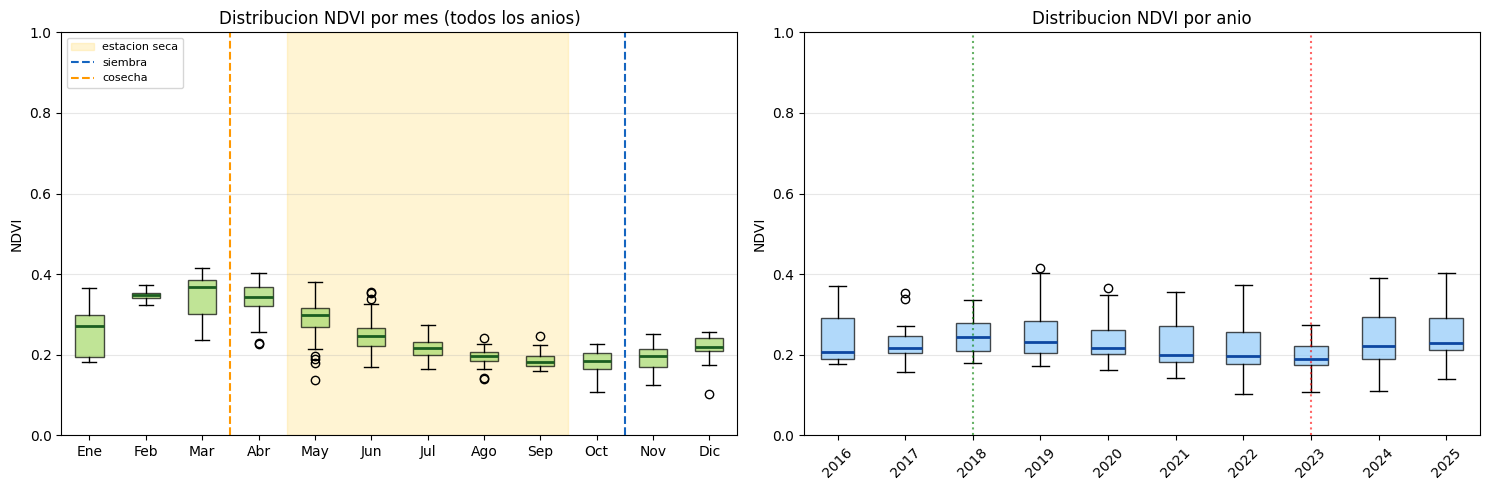

Anio con mediana NDVI mas BAJA: 2023 (0.190)
Anio con mediana NDVI mas ALTA: 2018 (0.243)
Amplitud interanual de la mediana: 0.053 NDVI


In [34]:
# ============================================================
# M7.3a Boxplot NDVI: distribucion por mes y por anio
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

df_box = df_ndvi.copy()
df_box["mes"]  = df_box.index.month
df_box["anio"] = df_box.index.year
df_box = df_box[df_box["anio"].isin(ANIOS_COMPLETOS)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: por mes
data_mes = [df_box[df_box["mes"] == m]["valor"].dropna().values for m in MESES]
bp1 = axes[0].boxplot(data_mes, labels=MESES_ES, patch_artist=True,
                      boxprops=dict(facecolor="#a6d96a", alpha=0.7),
                      medianprops=dict(color="#1b5e20", lw=2))
axes[0].axvspan(4.5, 9.5, color="#ffe082", alpha=0.35, label="estacion seca")
axes[0].axvline(CALENDARIO["siembra"] - 0.5, color="#1565c0", ls="--", label="siembra")
axes[0].axvline(CALENDARIO["cosecha"] - 0.5, color="#ff9800", ls="--", label="cosecha")
axes[0].set_title("Distribucion NDVI por mes (todos los anios)")
axes[0].set_ylabel("NDVI"); axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, axis="y")

# Panel B: por anio
anios_box = sorted(df_box["anio"].unique())
data_anio = [df_box[df_box["anio"] == y]["valor"].dropna().values for y in anios_box]
mediana_anual = [np.median(d) if len(d) else np.nan for d in data_anio]
bp2 = axes[1].boxplot(data_anio, labels=anios_box, patch_artist=True,
                      boxprops=dict(facecolor="#90caf9", alpha=0.7),
                      medianprops=dict(color="#0d47a1", lw=2))
axes[1].set_title("Distribucion NDVI por anio")
axes[1].set_ylabel("NDVI"); axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3, axis="y")
# Anota min y max
y_min = anios_box[int(np.nanargmin(mediana_anual))]
y_max = anios_box[int(np.nanargmax(mediana_anual))]
axes[1].axvline(anios_box.index(y_min) + 1, color="red", ls=":", alpha=0.6)
axes[1].axvline(anios_box.index(y_max) + 1, color="green", ls=":", alpha=0.6)

plt.tight_layout(); plt.show()

print(f"Anio con mediana NDVI mas BAJA: {y_min} ({np.nanmin(mediana_anual):.3f})")
print(f"Anio con mediana NDVI mas ALTA: {y_max} ({np.nanmax(mediana_anual):.3f})")
print(f"Amplitud interanual de la mediana: "
      f"{np.nanmax(mediana_anual) - np.nanmin(mediana_anual):.3f} NDVI")

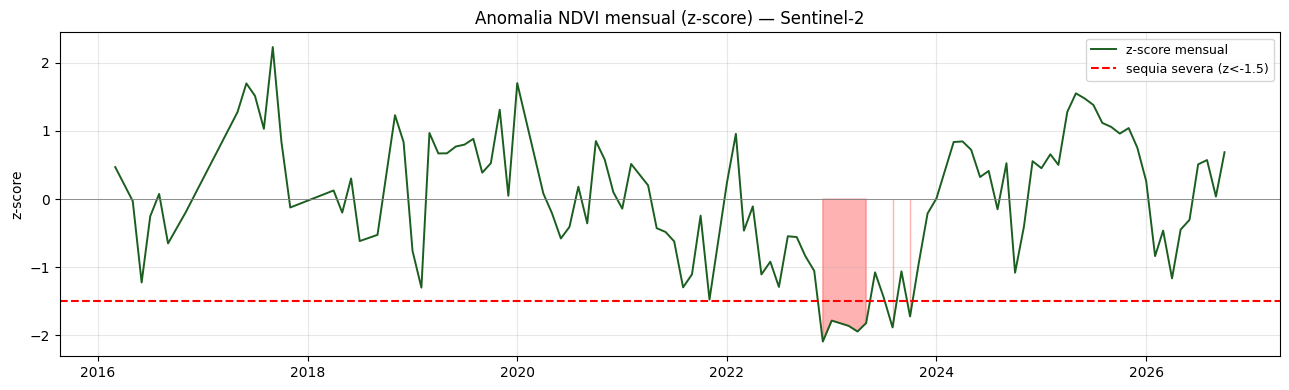

Meses con anomalia severa (z < -1.5): 7
fecha
2022-12-01   -2.09
2023-01-01   -1.78
2023-03-01   -1.86
2023-04-01   -1.94
2023-05-01   -1.82
2023-08-01   -1.88
2023-10-01   -1.72


In [35]:
# ============================================================
# M7.3b Anomalia z-score NDVI (usa UMBRALES['ndvi_anomalia_z'])
# ============================================================
anios_z = sorted(df_ndvi.index.year.unique())
clim_z, desv_z = {}, {}
for m in MESES:
    vals = [df_ndvi[(df_ndvi.index.year == y) & (df_ndvi.index.month == m)]["valor"].mean()
            for y in anios_z]
    vals = [v for v in vals if pd.notna(v)]
    if len(vals) >= 3:
        clim_z[m] = float(np.mean(vals))
        desv_z[m] = float(np.std(vals, ddof=1))

df_z = df_ndvi.copy()
df_z["mes"]  = df_z.index.month
df_z["clim"] = df_z["mes"].map(clim_z)
df_z["desv"] = df_z["mes"].map(desv_z)
df_z["z"]    = (df_z["valor"] - df_z["clim"]) / df_z["desv"]

z_mensual = df_z.resample("MS")["z"].mean().dropna()
umbral_z = UMBRALES["ndvi_anomalia_z"]
anom_severa = z_mensual[z_mensual < umbral_z]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(z_mensual.index, z_mensual.values, lw=1.4, color="#1b5e20", label="z-score mensual")
ax.axhline(0, color="gray", lw=0.6)
ax.axhline(umbral_z, color="red", ls="--", label=f"sequia severa (z<{umbral_z})")
ax.fill_between(z_mensual.index, z_mensual.values, 0,
                where=(z_mensual.values < umbral_z), color="red", alpha=0.3)
ax.set_title("Anomalia NDVI mensual (z-score) — Sentinel-2")
ax.set_ylabel("z-score"); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"Meses con anomalia severa (z < {umbral_z}): {len(anom_severa)}")
if len(anom_severa):
    print(anom_severa.round(2).to_string())

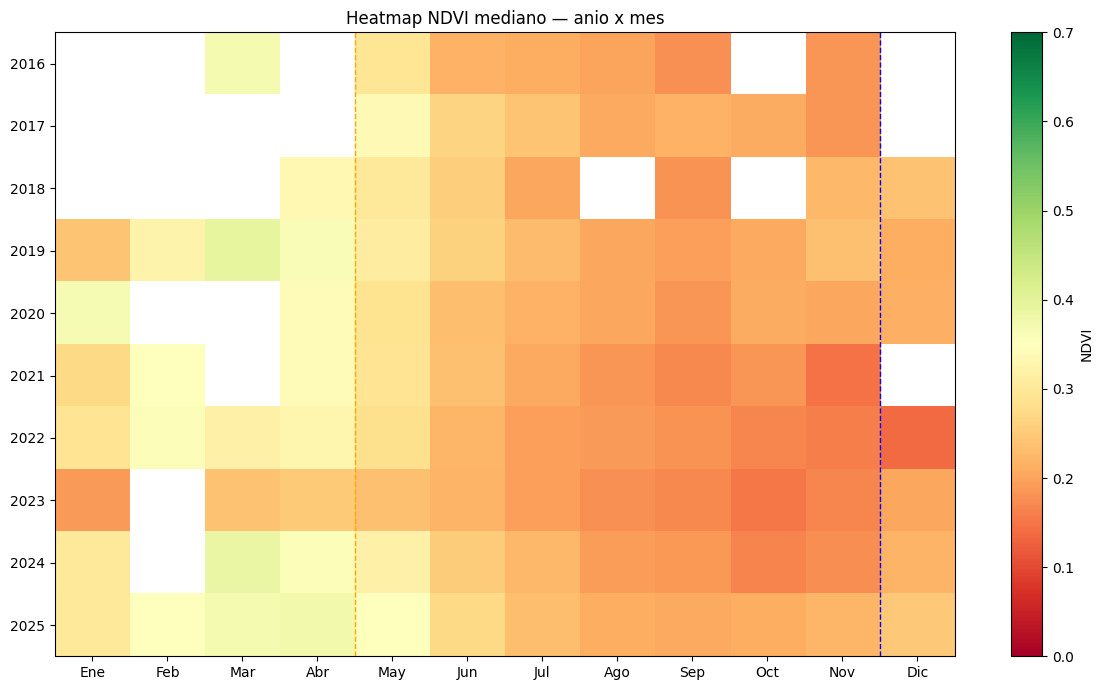

Anio mas SECO por NDVI:   2023 (0.195)
Anio mas HUMEDO por NDVI: 2025 (0.260)


In [38]:
# ============================================================
# M7.3e Heatmap NDVI: anio (fila) x mes (columna)
# ============================================================
matriz = (df_ndvi.assign(anio=df_ndvi.index.year, mes=df_ndvi.index.month)
                 .groupby(["anio", "mes"])["valor"].median()
                 .unstack("mes").reindex(columns=MESES))

# Filtra solo anios completos
matriz = matriz.loc[matriz.index.isin(ANIOS_COMPLETOS)]

fig, ax = plt.subplots(figsize=(12, 0.5 * len(matriz) + 2))
im = ax.imshow(matriz.values, aspect="auto", cmap="RdYlGn",
               vmin=0.0, vmax=0.7)
ax.set_xticks(range(12)); ax.set_xticklabels(MESES_ES)
ax.set_yticks(range(len(matriz))); ax.set_yticklabels(matriz.index)
ax.set_title("Heatmap NDVI mediano — anio x mes")
# Marca siembra y cosecha
ax.axvline(CALENDARIO["siembra"] - 0.5, color="blue", ls="--", lw=1)
ax.axvline(CALENDARIO["cosecha"] - 0.5, color="orange", ls="--", lw=1)
plt.colorbar(im, ax=ax, label="NDVI")
plt.tight_layout(); plt.show()

# Anios mas secos y mas humedos por NDVI (no por lluvia)
ndvi_anual = matriz.median(axis=1).dropna()
print(f"Anio mas SECO por NDVI:   {ndvi_anual.idxmin()} "
      f"({ndvi_anual.min():.3f})")
print(f"Anio mas HUMEDO por NDVI: {ndvi_anual.idxmax()} "
      f"({ndvi_anual.max():.3f})")